# Mini-Challenge DEL: Hyperparameter Tuning und Model Evaluation

**Aaron Studer** · BSc Data Science FHNW · HS26

Ich klassifiziere Sentinel-2-Satellitenbilder aus dem EuroSAT-Datensatz in 10 Landnutzungsklassen.

Der wiederverwendbare Code liegt in `src/delmc/`, sonst wäre das Notebook voller Boilerplate. Jeder
Trainingslauf wird als JSON unter `results/` abgelegt, die Plots werden daraus gezeichnet. Das hat
einen praktischen Grund: ich habe alles auf der CPU gerechnet, und die Läufe zusammen haben mehrere
Stunden gebraucht. Zum Durchlesen muss davon nichts wiederholt werden.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torchinfo import summary

from delmc.data import EuroSATDataModule
from delmc.engine import History, Trainer
from delmc.experiments import ResultCache
from delmc.models import CNNConfig, ConfigurableCNN
from delmc.reporting import (overfitting_summary, per_class_table, plot_class_performance,
                             plot_confusion_matrix, plot_learning_curves, plot_metric_vs_hyperparameter,
                             plot_overfit_test, plot_overfitting_analysis, summary_table)
from delmc.utils import seed_everything, select_device

SEED = 42
seed_everything(SEED)
device = select_device()
cache = ResultCache()
print(torch.__version__, device)

2.14.0+xpu cpu


/home/taastaa1/miniconda3/envs/ml-bachelor-del/lib/python3.13/site-packages/torch/xpu/__init__.py:278: UserWarning: XPU device count is zero! (Triggered internally at /__w/pytorch/pytorch/c10/xpu/XPUFunctions.cpp:113.)
  count = torch._C._xpu_getDeviceCount() if zes_count < 0 else zes_count


## 1. Was ich hier mache

Ich baue ein Basismodell auf und bringe die Infrastruktur zum Laufen. Also Daten anschauen,
Preprocessing festlegen, Metriken wählen, Trainings- und Evaluationsschleife schreiben, Tracking nach
Weights & Biases. Dazu ein Overfitting-Test auf einem einzelnen Batch, mit dem ich prüfe, ob die
Mechanik stimmt.

Dann wird das Basismodell mit reinem SGD trainiert, ohne Momentum, ohne Regularisierung, ohne
BatchNorm. Lernrate und Batchsize tune ich von Hand aus den Lernkurven, automatische Suchverfahren
sind laut Aufgabenstellung nicht erlaubt. Mit Cross-Validation schätze ich ab, wie stark die Resultate
überhaupt schwanken.

Danach kommen die Hypothesen zu Modellkomplexität, Conv-Settings, Regularisierung, BatchNorm,
Initialisierung, Adam und Transfer Learning, und am Schluss ein Modell aus den Varianten, die sich
bewährt haben.

## 2. Daten

### 2.1 Datensatz EuroSAT

EuroSAT besteht aus Sentinel-2-Aufnahmen mit 10 m Bodenauflösung, zugeschnitten auf 64 × 64 Pixel. Ein
Bild deckt damit etwas mehr als einen halben Kilometer im Quadrat ab. Dass ein Pixel 10 m entspricht,
wird später bei der Kernel Size nochmal wichtig.

Ich habe den Datensatz genommen, weil er klein ist und ich damit viele Varianten durchrechnen kann,
ohne lange mit Datenbeschaffung beschäftigt zu sein. Beim Transfer Learning fand ich ausserdem
spannend, dass das Ergebnis offen ist. Satellitenbilder von oben sind etwas ziemlich anderes als die
Fotos in ImageNet. Und bei der Data Augmentation habe ich ein Argument, das über "hilft meistens"
hinausgeht: ein Luftbild hat keine feste Orientierung, gespiegelt oder gedreht bleibt das Label
dasselbe.

In [2]:
dm = EuroSATDataModule(root="../data", seed=SEED, num_workers=4).prepare()
pd.Series(dm.class_counts("all"), name="Bilder")

AnnualCrop              3000
Forest                  3000
HerbaceousVegetation    3000
Highway                 2500
Industrial              2500
Pasture                 2000
PermanentCrop           2500
Residential             3000
River                   2500
SeaLake                 3000
Name: Bilder, dtype: int64

### 2.2 Explorative Analyse

Die Klassen sind leicht unbalanciert. Für Resampling ist mir der Unterschied zu klein. Der Accuracy
allein traue ich trotzdem nicht ganz, deshalb berichte ich zusätzlich Macro-F1.

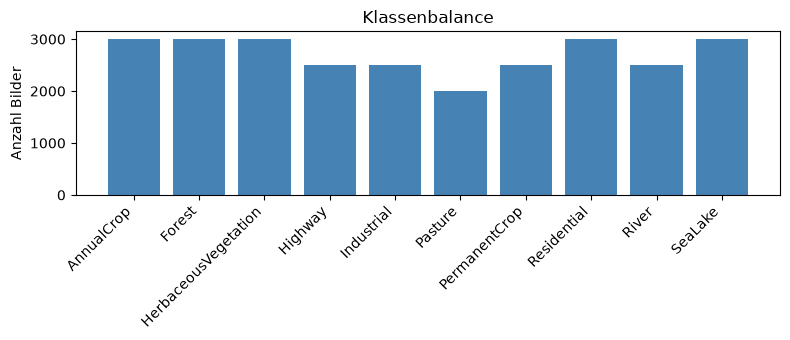

In [3]:
counts = dm.class_counts("all")
figure, axis = plt.subplots(figsize=(8, 3.5))
axis.bar(counts.keys(), counts.values(), color="steelblue")
axis.set_ylabel("Anzahl Bilder"), axis.set_title("Klassenbalance")
axis.tick_params(axis="x", rotation=45)
plt.setp(axis.get_xticklabels(), ha="right")
figure.tight_layout()

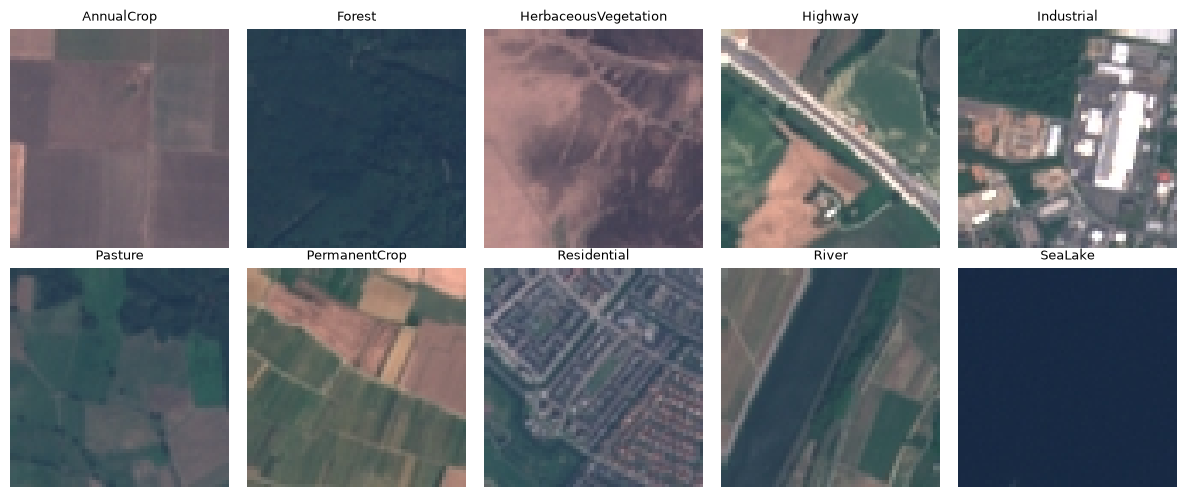

In [4]:
# Je ein Beispielbild pro Klasse.
raw = dm._raw
targets = dm.targets
figure, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_index, axis in enumerate(axes.flat):
    position = int(np.where(targets == class_index)[0][0])
    axis.imshow(raw[position][0])
    axis.set_title(dm.class_names[class_index], fontsize=9)
    axis.axis("off")
figure.tight_layout()

Die vier Vegetationsklassen sehen auf den Beispielbildern ziemlich ähnlich aus, alles grüne Flächen
mit unterschiedlicher Textur. Ich würde erwarten, dass die Confusion Matrix später genau dort die
meisten Fehler zeigt.

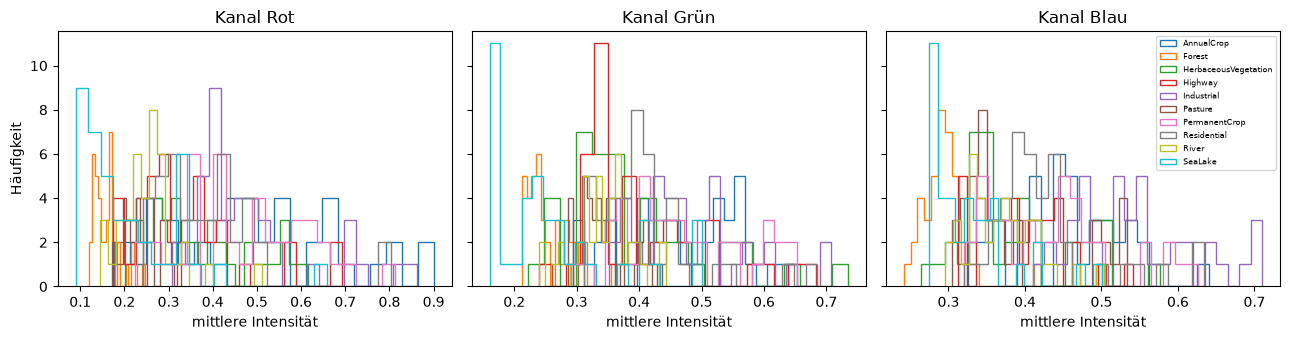

In [5]:
# Intensitätsverteilung pro Kanal und Klasse, auf einer Stichprobe.
rng = np.random.default_rng(SEED)
figure, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for channel, (axis, label) in enumerate(zip(axes, ["Rot", "Grün", "Blau"])):
    for class_index, class_name in enumerate(dm.class_names):
        positions = rng.choice(np.where(targets == class_index)[0], size=40, replace=False)
        values = [np.asarray(raw[int(p)][0], dtype=np.float32)[:, :, channel].mean() / 255 for p in positions]
        axis.hist(values, bins=20, histtype="step", label=class_name)
    axis.set_title(f"Kanal {label}"), axis.set_xlabel("mittlere Intensität")
axes[0].set_ylabel("Häufigkeit")
axes[2].legend(fontsize=6, loc="upper right")
figure.tight_layout()

### 2.3 Preprocessing

Normalisierung pro Kanal. Die Statistiken rechne ich nur auf dem Trainings-Split, sonst leckt
Information aus Validierung und Test in die Eingaben.

In [6]:
mean, std = dm.normalization
pd.DataFrame({"Mittelwert": mean, "Std": std}, index=["Rot", "Grün", "Blau"]).round(4)

,Mittelwert,Std
Rot,0.3439,0.2024
Grün,0.3800,0.1367
Blau,0.4075,0.1154


Auffällig ist, dass die Standardabweichung von Rot nach Blau deutlich abfällt. Bei normalen Fotos
liegen die Kanäle näher zusammen. Ich vermute atmosphärische Streuung, die den Blaukanal
gleichförmiger macht, nachgeprüft habe ich das aber nicht.

### 2.4 Split

Stratifiziert 70 / 15 / 15 mit festem Seed. Das Testset fasse ich bis zur finalen Evaluation nicht an.

In [7]:
split_tabelle = pd.DataFrame({split: dm.class_counts(split) for split in ("train", "val", "test")})
split_tabelle.loc["Total"] = split_tabelle.sum()
split_tabelle

,train,val,test
AnnualCrop,2100,450,450
Forest,2100,450,450
HerbaceousVegetation,2100,450,450
Highway,1750,375,375
Industrial,1750,375,375
Pasture,1400,300,300
PermanentCrop,1750,375,375
Residential,2100,450,450
River,1750,375,375
SeaLake,2100,450,450


## 3. Metriken für die Evaluation

| Metrik | Warum |
|---|---|
| Accuracy | Hauptmetrik, vergleichbar mit der EuroSAT-Literatur |
| Macro-F1 | gewichtet alle Klassen gleich, wegen der Unbalance |
| Confusion Matrix | zeigt, welche Klassen verwechselt werden |
| Cross-Entropy | Kostenfunktion, auf den Logits gerechnet |

Bei einzelnen Experimenten schaue ich zusätzlich den F1 pro Klasse an, zum Beispiel beim Pooling. Dort
erwarte ich, dass der Effekt nicht alle Klassen gleich trifft.

## 4. Basisfunktionalität

`delmc.engine.Trainer` enthält Trainings- und Evaluationsschleife, `delmc.experiments` das Caching der
Resultate, `delmc.probes` die Gradienten-Messung für die Frage nach verschwindenden Gradienten weiter
hinten. Getrackt wird nach Weights & Biases.

## 5. Basismodell

### 5.1 Architektur

Ein paar Conv-Layer für die Features, zwei FC-Layer für die Klassifikation. Die Zahl der
Pooling-Stufen halte ich fix bei drei. Wenn ich später die Tiefe variiere, soll sich die räumliche
Reduktion nicht mitverändern, sonst weiss ich am Ende nicht, woher ein Effekt kommt.

In [8]:
basis = CNNConfig(stage_widths=(32, 64, 128), fc_widths=(256,))
modell = ConfigurableCNN(basis)
summary(modell, input_size=(1, 3, 64, 64), col_names=("output_size", "num_params"), depth=3)

Layer (type:depth-idx)                   Output Shape              Param #
ConfigurableCNN                          [1, 10]                   --
├─Sequential: 1-1                        [1, 128, 8, 8]            --
│    └─ConvStage: 2-1                    [1, 32, 32, 32]           --
│    │    └─Sequential: 3-1              [1, 32, 64, 64]           896
│    │    └─MaxPool2d: 3-2               [1, 32, 32, 32]           --
│    └─ConvStage: 2-2                    [1, 64, 16, 16]           --
│    │    └─Sequential: 3-3              [1, 64, 32, 32]           18,496
│    │    └─MaxPool2d: 3-4               [1, 64, 16, 16]           --
│    └─ConvStage: 2-3                    [1, 128, 8, 8]            --
│    │    └─Sequential: 3-5              [1, 128, 16, 16]          73,856
│    │    └─MaxPool2d: 3-6               [1, 128, 8, 8]            --
├─Sequential: 1-2                        [1, 10]                   --
│    └─Flatten: 2-4                      [1, 8192]                 --
│    └

Beim Blick auf die Parameterzahlen war ich kurz verwirrt. Fast alles liegt im ersten FC-Layer, die
drei Conv-Layer zusammen machen nur ein paar Prozent aus. Nach drei Pooling-Stufen kommen eben immer
noch über achttausend Werte an, die auf 256 Units abgebildet werden. Die Kapazität zum Auswendiglernen
sitzt damit im Klassifikationskopf. Beim Dropout schaue ich später zuerst dort hin.

### 5.2 Overfitting-Test

Die Aufgabenstellung verlangt, das Basismodell auf einem einzigen Batch zu trainieren, um die
Basisfunktionalität zu testen. Ich mache das wie im Kurs-Notebook zur MLP-Klassifikation: mit demselben
reinen SGD wie beim Basismodell und der Lernrate 0.03, die ich auch später fürs Training verwende. Neben
dem Batch zeichne ich zusätzlich die Validierung auf.

Damit zeigt der Test zwei Dinge. Lernt das Modell den Batch, funktionieren Schleife, Kostenfunktion und
Label-Zuordnung. Und an der Validierung sieht man, was das Auswendiglernen eines Batches für
ungesehene Bilder bringt.

Als Batch nehme ich ein Bild pro Klasse, damit jede Klasse im Test vorkommt. Bei einem zufälligen Batch
wäre das nicht garantiert. Validiert wird auf 100 Bildern pro Klasse, so ergibt Raten genau 0.1.

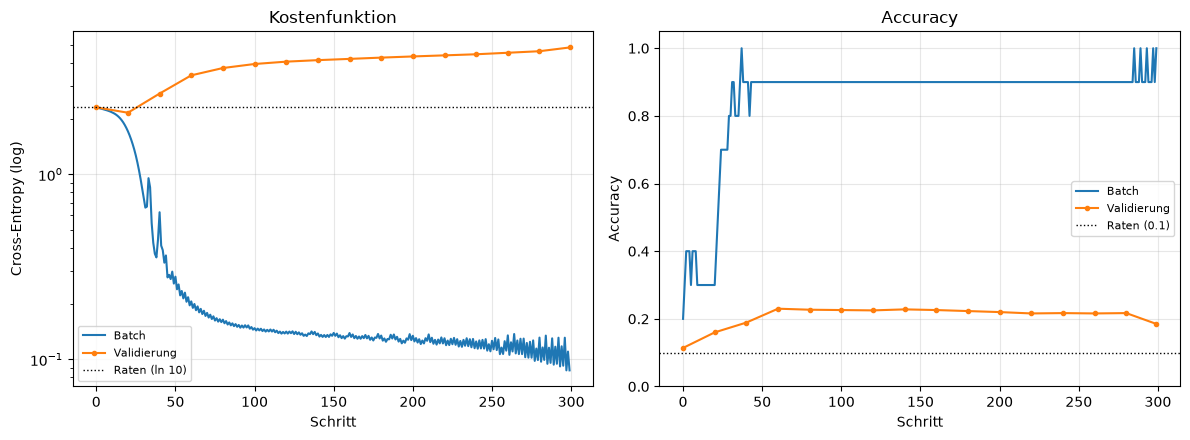

,Batch,Validierung
Kosten Start,2.303,2.299
Kosten Ende,0.087,4.840
beste Accuracy,1.000,0.230


In [9]:
# Ein Bild pro Klasse aus dem Trainings-Split, damit im Test jede Klasse einmal vorkommt.
train, val = dm.split.train, dm.split.val
ein_bild_pro_klasse = [int(train[dm.targets[train] == k][0]) for k in range(dm.num_classes)]
batch_loader = dm.subset_loader(ein_bild_pro_klasse, shuffle=False, batch_size=10)

# 100 Validierungsbilder pro Klasse, Raten ergibt hier genau 0.1.
val_auswahl = np.concatenate([val[dm.targets[val] == k][:100] for k in range(dm.num_classes)])
val_loader = dm.subset_loader(val_auswahl, shuffle=False, batch_size=250)

seed_everything(SEED)
test_modell = ConfigurableCNN(basis)
test_trainer = Trainer(model=test_modell, optimizer=torch.optim.SGD(test_modell.parameters(), lr=0.03),
                       device=device, num_classes=dm.num_classes)
overfit = test_trainer.overfit_batch(batch_loader, steps=300, val_loader=val_loader, eval_every=20)

plot_overfit_test(overfit)
plt.show()

pd.DataFrame({
    "Batch": [overfit.losses[0], overfit.losses[-1], max(overfit.accuracies)],
    "Validierung": [overfit.val_losses[0], overfit.val_losses[-1], max(overfit.val_accuracies)],
}, index=["Kosten Start", "Kosten Ende", "beste Accuracy"]).round(3)

Die Mechanik funktioniert. Auf dem Batch fallen die Kosten um mehr als eine Zehnerpotenz, und nach rund
40 Schritten sind neun von zehn Bildern richtig. Das zehnte bleibt danach lange hängen und wird erst
gegen Ende zeitweise richtig klassifiziert. Die Kurve auf dem Batch zeigt dabei ein feines
Sägezahnmuster. Da der Batch fest ist, kommt das nicht von zufälligen Daten. Ich erkläre es mir so,
dass reines SGD mit fester Lernrate in einem schmalen Tal hin und her springt, statt hinunterzulaufen.
Varianten wie Momentum, die genau das dämpfen sollen, schaue ich mir bei den Hypothesen an.

Auf der Validierung passiert fast nichts. Die Accuracy bleibt knapp über dem Raten, und die Kosten
steigen sogar deutlich über das Niveau von blindem Raten. Das Modell wird auf ungesehenen Bildern also
zunehmend sicher, liegt aber trotzdem falsch. Das ist dasselbe Muster wie später im richtigen Training,
nur viel extremer, weil zehn Bilder nichts Allgemeines enthalten, das sich lernen liesse.

### 5.3 Wahl der Kapazität

Zwei Grössen, `base` und `wide`, unter gleichen Bedingungen über 40 Epochen.

,Run,Parameter,Conv-Tiefe,Epoche,Train-Accuracy,Val-Accuracy,Gap,Val-Macro-F1,Train-Loss,Val-Loss,s/Epoche
0,wide,8765066,None,39,0.983,0.817,0.165,0.810,0.058,0.783,54.402
1,base,2193226,None,39,0.987,0.782,0.205,0.776,0.054,0.855,50.536


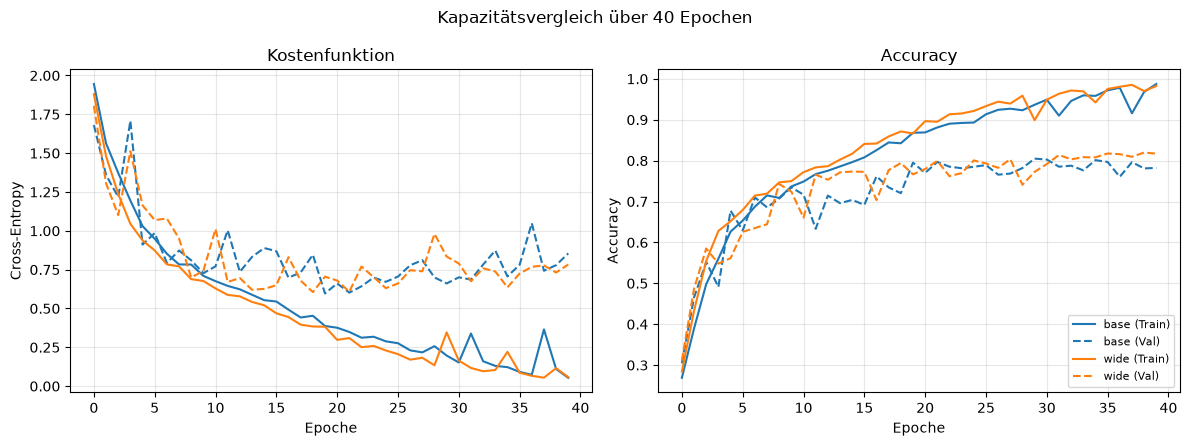

In [10]:
kapazitaet = cache.group("h0-kapazitaet-lang")
display(summary_table(kapazitaet).style.format(precision=3))
plot_learning_curves(kapazitaet, "Kapazitätsvergleich über 40 Epochen")
plt.show()

Das Ergebnis hatte ich so nicht erwartet. `wide` hat rund viermal so viele Parameter wie `base`, kommt
aber auf die höhere Validierungs-Accuracy, und der Gap ist dabei sogar kleiner. Ich war von "mehr
Parameter, mehr Overfitting" ausgegangen.

Beide lernen den Trainings-Split am Ende gleich gut auswendig. Die zusätzliche Kapazität scheint also
in bessere Features zu gehen statt in mehr Memorisierung. Bei dieser Datenmenge sind wir offenbar noch
nicht an dem Punkt, wo zusätzliche Parameter schaden. Bei der Deutung bin ich mir allerdings nicht
sicher, dafür habe ich zu wenige Grössen verglichen.

Dazu kommen zwei Einschränkungen. `wide` erreicht sein Bestergebnis erst in den letzten Epochen, war
also noch gar nicht fertig. Und der Unterschied liegt nur knapp über der Streuung, die weiter unten
aus der Cross-Validation kommt.

Als Basismodell nehme ich trotzdem `base`. Es ist pro Epoche deutlich schneller, und davon weichen
später dutzende Varianten ab. Auf der CPU ist das der Unterschied zwischen einer Nacht und drei.

### 5.4 Training des Basismodells und Overfitting-Analyse

Wie verlangt mit SGD ohne Momentum, ohne Regularisierung, ohne BatchNorm. Die dünnen Linien sind
die Werte pro Epoche, die dicken ein gleitender Mittelwert über fünf Epochen. Rot markiert ist der
Bereich, in dem die geglätteten Val-Kosten wieder steigen.

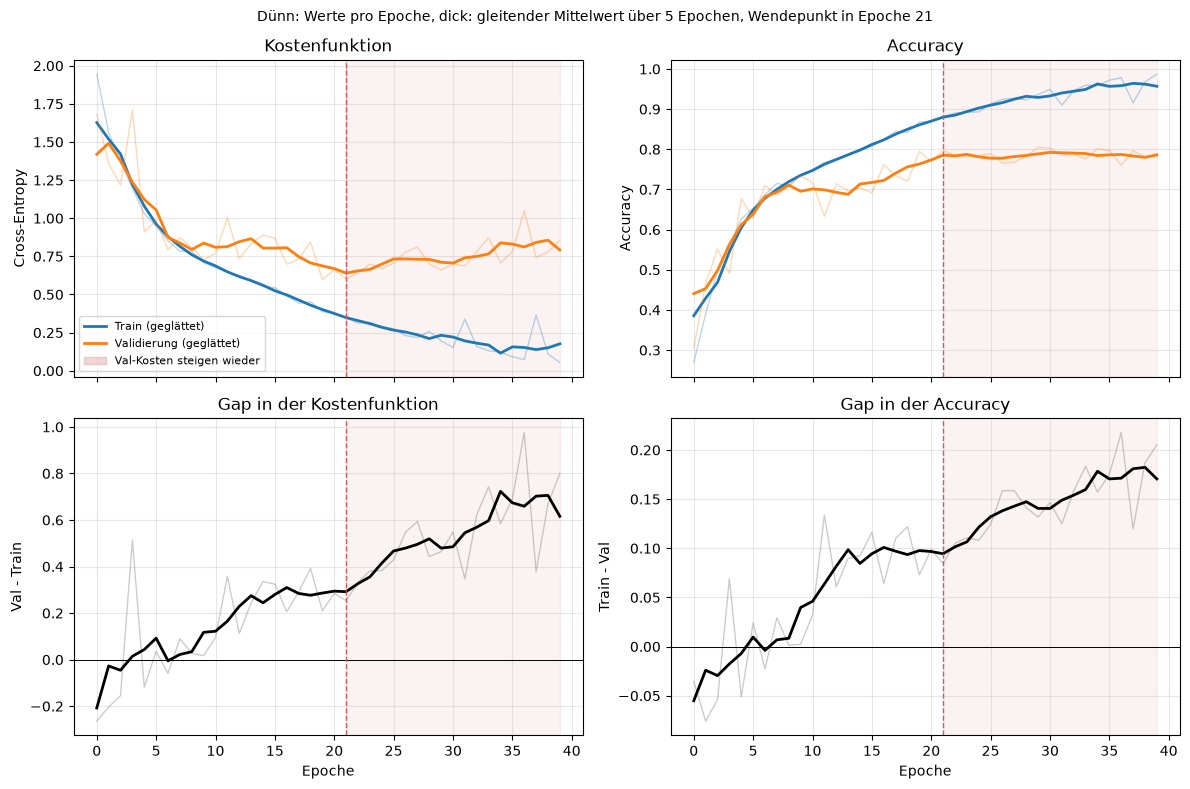

,Epoche,Train-Kosten,Val-Kosten,Val-Kosten geglättet,Train-Accuracy,Val-Accuracy
Zeitpunkt,,,,,,
Start,0,1.945,1.681,1.419,0.269,0.304
Wendepunkt,21,0.349,0.602,0.640,0.881,0.797
Ende,39,0.054,0.855,0.792,0.987,0.782


In [11]:
basis_lauf = kapazitaet["base"]
plot_overfitting_analysis(basis_lauf, window=5)
plt.show()
display(overfitting_summary(basis_lauf, window=5).style.format(precision=3))

Am Ende kennt das Modell den Trainings-Split fast vollständig, die Kosten dort gehen gegen null. Die
Validierung bleibt dagegen bei knapp 0.8 hängen.

Die rohen Validierungs-Kurven springen von Epoche zu Epoche ziemlich stark, bei den Kosten gibt es
mehrere einzelne Ausreisser nach oben. Wenn ich das Minimum direkt aus den rohen Werten ablese, liegen
mehrere Epochen fast gleich tief, und welche davon gewinnt, ist Zufall. Deshalb lese ich den Verlauf an
den geglätteten Kurven ab. Prechelt (1998) beschreibt genau dieses Problem: echte Validierungs-Kurven
haben mehrere lokale Minima, und ein Kriterium auf Einzelwerten ist unzuverlässig.

Im geglätteten Verlauf sehe ich drei Abschnitte.

Bis etwa Epoche 9 liegen Train und Validierung praktisch aufeinander, der Gap schwankt um null. Das
Modell lernt Dinge, die auf beiden Splits gleich gut funktionieren.

Ab Epoche 9 öffnet sich der Gap, in der Accuracy und in den Kosten. Die Val-Accuracy steigt trotzdem
weiter, nur langsamer als beim Training, während die Val-Kosten eine Weile auf einem Plateau bleiben.
Das Modell passt sich hier also schon stärker an die Trainingsdaten an, weiteres Training bringt aber
noch etwas.

Ab Epoche 21 schadet es. Dort erreichen die geglätteten Val-Kosten ihr Minimum und steigen danach
wieder, während die Trainingskosten weiter Richtung null fallen. Die Val-Accuracy bleibt auf einem
Plateau. Das Modell wird also auf den Trainingsdaten besser und auf der Validierung schlechter, und das
ist für mich das eigentliche Argument für Overfitting.

Dass die Kosten steigen, während die Accuracy nicht fällt, hat mich zuerst irritiert. Meine Erklärung
ist, dass das Modell bei den Bildern, die es falsch klassifiziert, immer sicherer wird. Die
Cross-Entropy bestraft eine sichere falsche Vorhersage stark, für die Accuracy ist falsch einfach
falsch. Guo et al. (2017) beschreiben denselben Effekt bei grösseren Netzen. Nachgemessen habe ich das
bei mir nicht, dafür müsste ich die Konfidenz der falschen Vorhersagen über die Epochen verfolgen.

Für Early Stopping würde ich mich deshalb an den Val-Kosten orientieren. Und die Lücke zwischen Train
und Validierung ist das, was die Regularisierung später verkleinern soll.

## 6. Tuning von Lernrate und Batchsize

Manuelles log-Gitter, kein automatisches Suchverfahren.

### 6.1 Lernrate

,Run,Parameter,Conv-Tiefe,Epoche,Train-Accuracy,Val-Accuracy,Gap,Val-Macro-F1,Train-Loss,Val-Loss,s/Epoche
0,lr-0.03,2193226,None,14,0.796,0.704,0.092,0.692,0.554,0.889,32.674
1,lr-0.1,2193226,None,14,0.890,0.672,0.217,0.658,0.332,1.106,33.392
2,lr-0.01,2193226,None,14,0.732,0.603,0.129,0.581,0.733,1.150,47.447
3,lr-0.003,2193226,None,14,0.535,0.524,0.011,0.473,1.253,1.279,47.952


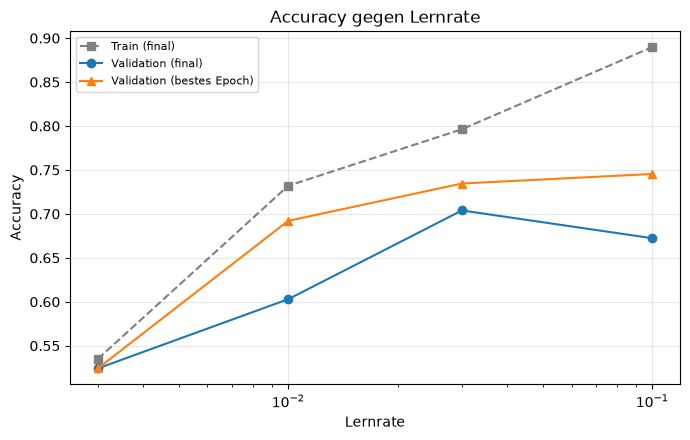

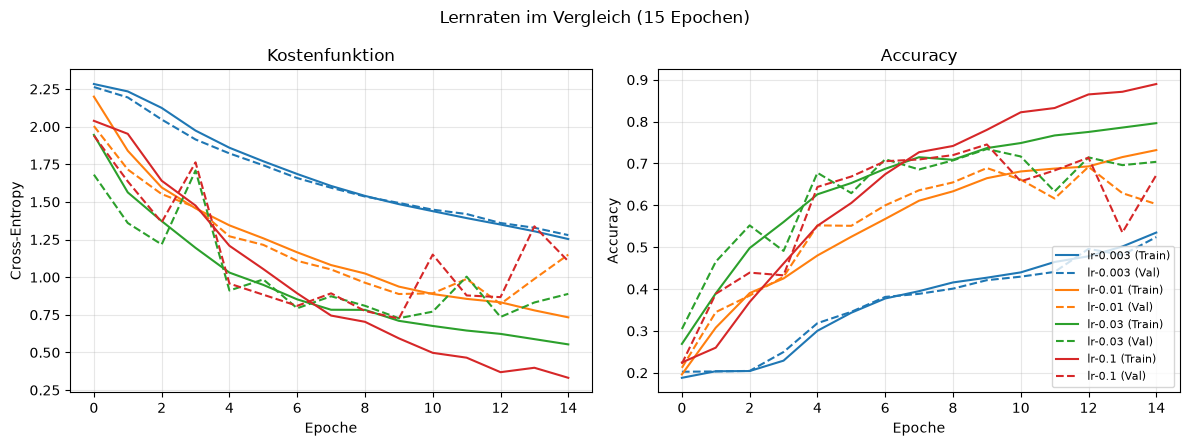

In [12]:
lernraten = cache.group("h0-lernrate")
display(summary_table(lernraten).style.format(precision=3))
plot_metric_vs_hyperparameter(lernraten, "lr", "Lernrate")
plt.show()
plot_learning_curves(lernraten, "Lernraten im Vergleich (15 Epochen)")
plt.show()

Ungefähr so, wie man es aus der Theorie erwarten würde.

Die kleinste Lernrate ist zu klein. Train und Validierung liegen beide tief und nah beieinander, das
Modell unterlernt. Die Schrittweite reicht im Epochenbudget nicht aus.

In der Mitte bekomme ich die beste finale Accuracy bei ruhigem Verlauf.

Die grösste Lernrate erreicht das höchste Zwischenmaximum, fällt danach aber wieder merklich zurück.
Für mich sieht das nach Instabilität aus und nicht bloss nach Overfitting, weil die Schritte über das
Minimum hinausspringen. Das würde zum Initialisierungs-Befund von weiter oben passen, wo sich die
schlechte Konditionierung auch zuerst bei grossen Schritten gezeigt hat. Nachweisen kann ich das hier
nicht, dafür müsste ich die Gradientennormen über den Verlauf anschauen.

Der Gap wächst insgesamt mit der Lernrate. Ich nehme den mittleren Wert.

### 6.2 Batchsize

,Run,Parameter,Conv-Tiefe,Epoche,Train-Accuracy,Val-Accuracy,Gap,Val-Macro-F1,Train-Loss,Val-Loss,s/Epoche
0,batch-32,2193226,None,19,0.965,0.808,0.157,0.803,0.119,0.681,89.542
1,batch-64,2193226,None,19,0.868,0.795,0.073,0.790,0.387,0.597,50.917
2,batch-128,2193226,None,19,0.752,0.695,0.057,0.691,0.673,0.830,23.134
3,batch-256,2193226,None,19,0.684,0.659,0.025,0.651,0.862,0.945,23.880


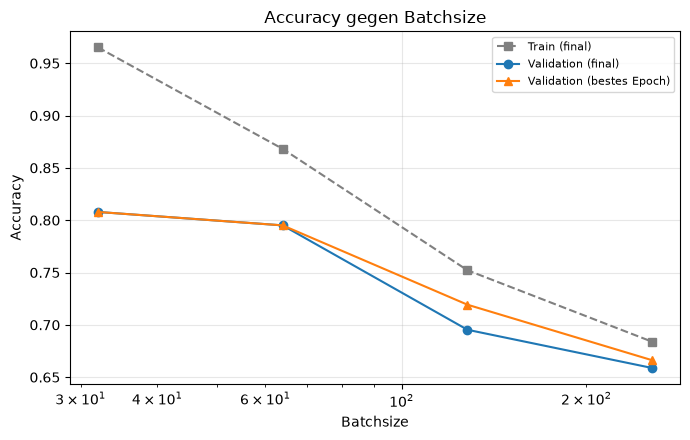

In [13]:
batchsizes = cache.group("h0-batchsize")
display(summary_table(batchsizes).style.format(precision=3))
plot_metric_vs_hyperparameter(batchsizes, "batch_size", "Batchsize")
plt.show()

Die Accuracy fällt mit steigender Batchsize, der Gap wird kleiner. Das sieht auf den ersten Blick nach
einem Generalisierungseffekt aus, ist aber keiner.

Bei fixer Lernrate macht die grösste Batchsize pro Epoche achtmal weniger Parameter-Updates als die
kleinste. Im festen Epochenbudget kommt das Modell damit weniger weit, und man sieht es an der
Trainings-Accuracy, die bei den grossen Batches selbst noch tief bleibt. Ein Modell, das die
Trainingsdaten nicht trifft, hat nicht besser generalisiert, sondern weniger gelernt.

Sauber verglichen müsste die Lernrate mit der Batchsize mitskalieren, so wie es die lineare
Skalierungsregel von Goyal et al. (2017) vorschlägt. Mein Experiment vermischt Batchsize und effektive
Schrittzahl. Belegen kann ich damit nur, dass bei dieser fixen Lernrate die kleineren Batches besser
abschneiden. Mit mehr Rechenzeit würde ich das nachholen.

Zur Rechenzeit noch: ab der dritten Stufe wird es nicht mehr schneller, da ist der
Parallelisierungsgewinn ausgereizt. Ich nehme 64, weil das praktisch gleich gut ist wie 32 und knapp
doppelt so schnell.

## 7. Schätzung des statistischen Fehlers

Fünffache stratifizierte Cross-Validation auf dem Trainings-Split. Das Testset bleibt unberührt.

,Accuracy,Macro-F1
Fold 0,0.7892,0.7832
Fold 1,0.7958,0.7888
Fold 2,0.7608,0.7537
Fold 3,0.7417,0.7353
Fold 4,0.7400,0.7206


,Accuracy,Macro-F1
mean,0.7655,0.7563
std,0.0261,0.0296


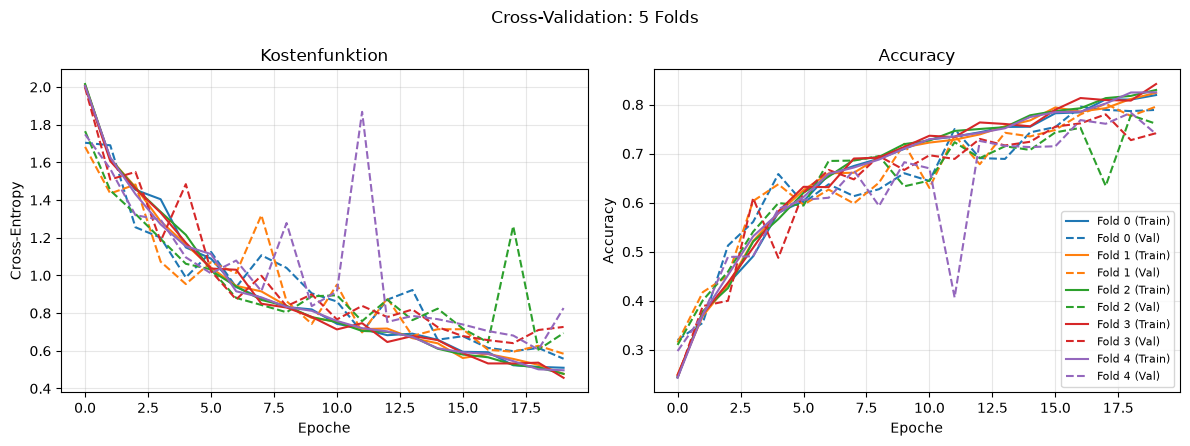

In [14]:
folds = {f"Fold {i}": History.load(f"../results/h0-crossval/fold-{i}.json") for i in range(5)}
cv = pd.DataFrame({
    "Accuracy": [h.records[-1].val_accuracy for h in folds.values()],
    "Macro-F1": [h.records[-1].val_macro_f1 for h in folds.values()],
}, index=list(folds))
display(cv.round(4))
display(cv.agg(["mean", "std"]).round(4))

plot_learning_curves(folds, "Cross-Validation: 5 Folds")
plt.show()

Die Streuung über die Folds liegt bei etwa zweieinhalb Prozentpunkten.

Diese Zahl hat im Nachhinein am meisten verändert, weil sie festlegt, welche Unterschiede ich
überhaupt interpretieren darf:

| Vergleich | Differenz | Einschätzung |
|---|---|---|
| `wide` gegen `base` | gut 3 pp | knapp über eine Standardabweichung, nicht belastbar |
| grösste gegen mittlere Lernrate | etwa 1 pp | im Rauschen |
| Batchsize 32 gegen 64 | gut 1 pp | im Rauschen |

Meine Rangfolgen aus 5.3 und 6 beruhen auf Einzelläufen und sind damit nicht belastbar. Ich lasse sie
stehen, weil die Richtung plausibel ist, würde aber keine Entscheidung darauf stützen, die an einem
Prozentpunkt hängt.

Für alles Weitere heisst das: enge Vergleiche brauchen mehrere Seeds.

## 8. Fehleranalyse: was gelingt, was nicht

Die aggregierten Metriken sagen nichts darüber, welche Klassen Probleme machen.

,Precision,Recall,F1,Support
Klasse,,,,
Residential,0.885,0.920,0.902,450
Industrial,0.879,0.893,0.886,375
SeaLake,0.773,0.976,0.862,450
AnnualCrop,0.854,0.767,0.808,450
Forest,0.977,0.658,0.786,450
Pasture,0.707,0.773,0.739,300
River,0.724,0.741,0.733,375
HerbaceousVegetation,0.699,0.764,0.730,450
PermanentCrop,0.643,0.696,0.668,375


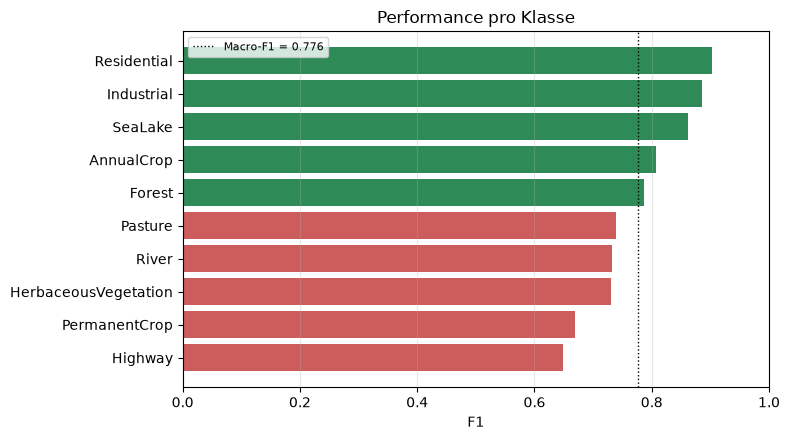

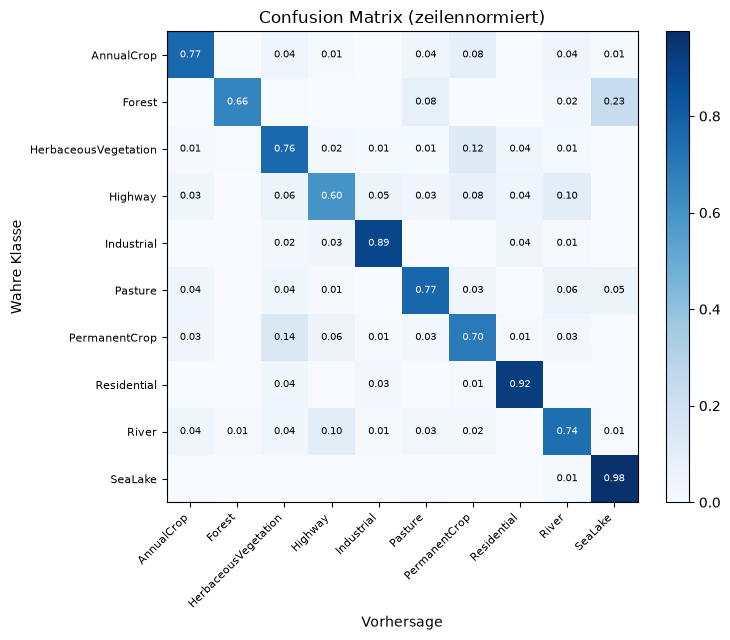

In [15]:
klassen_tabelle = per_class_table(basis_lauf.confusion, dm.class_names)
display(klassen_tabelle.style.format({"Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}"}))
plot_class_performance(basis_lauf.confusion, dm.class_names)
plt.show()
plot_confusion_matrix(basis_lauf.confusion, dm.class_names)
plt.show()

Gut funktionieren die baulichen Klassen, `Residential` und `Industrial`. Beide haben scharfe
geometrische Strukturen mit viel Kontrast, und damit scheint ein CNN mit wenigen Conv-Layern gut
zurechtzukommen.

Bei den schlechten Klassen sehe ich zwei verschiedene Probleme.

Das erste hatte ich erwartet, die Vegetationsklassen. `PermanentCrop` und `HerbaceousVegetation`
werden wechselseitig verwechselt, dazu kommt `AnnualCrop`. Alles grüne Flächen, die sich nur über
Textur und Parzellierung unterscheiden.

Das zweite war eine Überraschung. Die grösste einzelne Verwechslung ist `Forest` nach `SeaLake` und
betrifft fast ein Viertel aller Wald-Bilder. Wald und See sehen für mich eigentlich nicht ähnlich aus.
An Precision und Recall sieht man aber, was passiert: das Modell nennt kaum etwas fälschlich Wald,
übersieht dafür rund ein Drittel der echten Wälder, und `SeaLake` wird entsprechend zu oft
vorhergesagt.

Ich vermute, dass es an den Eingangsdaten liegt. Ich arbeite auf der RGB-Variante von EuroSAT, und
dichter Wald ist in RGB sehr dunkel und kaum texturiert, also durchaus ähnlich wie tiefes Wasser.
Trennen liessen sich die beiden wohl erst im nahen Infrarot, wo Vegetation stark reflektiert und
Wasser fast alles absorbiert. EuroSAT gibt es auch multispektral mit 13 Bändern. Nachgeprüft habe ich
das nicht, es passt nur zum Muster aus Precision und Recall. Wenn es stimmt, liegt es nicht an der
Architektur und Hyperparameter-Tuning bringt mich da nicht weiter.

Dann ist da noch `Highway`, meine schlechteste Klasse, die sich mit `River` gegenseitig verwechselt.
Beide sind schmale lineare Strukturen, die durch die Szene laufen. Bei 10 m Auflösung bleibt von einer
Strasse nicht viel mehr als ein paar Pixel Breite. Woran das Modell dort Asphalt von Wasser
unterscheiden soll, ist mir ehrlich gesagt nicht klar.

## 9. Zwischenfazit

Das Basismodell steht, drei Conv-Blöcke und zwei FC-Layer, mit dem Grossteil der Parameter im ersten
FC-Layer. Lernrate und Batchsize habe ich manuell aus den Lernkurven bestimmt.

Am meisten gebracht hat mir die Cross-Validation, weil sie mehrere meiner früheren Schlüsse
relativiert hat. Die Streuung ist der Massstab für alles Weitere.

Das Basismodell overfittet deutlich. Das ist so gewollt, sonst hätten die Regularisierungs-Experimente
nichts zu zeigen.

Bei den Fehlern konnte ich zwei Ursachen trennen. Die Vegetationsklassen sehen nach einem
Modellproblem aus, da geht es um Textur, und da könnte Tuning etwas bringen. Die Verwechslung von Wald
und Wasser sieht nach einem Datenproblem aus. Angehen kann ich im Folgenden nur das erste.

## 10. Hypothesen

### 10.0 Vorgehen

Bei jeder Hypothese ändere ich genau eine Sache am Basismodell. Alles andere bleibt wie oben: SGD ohne
Momentum, Lernrate 0.03, Batchsize 64, Default-Initialisierung, kein Dropout, keine Augmentation, 30
Epochen auf dem Trainings-Subset, gemessen auf dem vollen Validierungs-Split.

Was ich dabei vergleiche, sind Zufallsgrössen. Dieselbe Konfiguration startet mit einem anderen Seed
von einer anderen Initialisierung und sieht die Bilder in einer anderen Reihenfolge, und das Resultat
ist ein anderes. Ein einzelner Lauf pro Variante sagt deshalb wenig. Die Varianten, die ich
gegeneinander testen will, rechne ich mit drei Seeds und berichte Mittelwert und Standardabweichung.

Diese Seed-Streuung ist nicht dieselbe wie die Streuung aus der Cross-Validation in Abschnitt 7. Dort
hat sich der Datensplit verändert, hier bleibt er fest und es ändern sich nur Initialisierung und
Reihenfolge. Beides gehört zum Rauschen, gegen das sich ein Effekt durchsetzen muss.

Drei Seeds sind wenig. Ich werte einen Unterschied deshalb nur dann als Bestätigung, wenn alle drei
Läufe der einen Variante besser sind als alle drei der anderen. Gibt es in Wirklichkeit keinen
Unterschied, passiert das nur zufällig: von den 20 Möglichkeiten, sechs Werte auf zwei Gruppen zu je
drei zu verteilen, ist genau eine in der vorhergesagten Richtung vollständig getrennt. Das entspricht
einem einseitigen Test auf dem Niveau 1/20 = 0.05.

Die Kehrseite ist, dass ich kleine Effekte mit drei Seeds nicht nachweisen kann. Wenn sich zwei
Varianten überlappen, schreibe ich deshalb "nicht entscheidbar" und nicht "kein Effekt".

### 10.1 Hypothese 1: BatchNorm

#### Warum ich das untersuche

Das Basismodell musste laut Aufgabenstellung ohne BatchNorm trainiert werden, und in der ersten Etappe
hat sich gezeigt, was das kostet. Bei Lernrate 0.1 ist das Modell nach seinem besten Wert deutlich
zurückgefallen, und schon auf einem einzelnen Batch springt reines SGD mit fester Lernrate hin und
her (5.2).

Mich interessiert vor allem, *was* BatchNorm bei meinem Modell verbessert. Wenn es hauptsächlich das
Training stabilisiert, kann ich danach mit höheren Lernraten arbeiten. Wenn es zusätzlich
regularisiert, muss ich das später bei Dropout berücksichtigen, weil sich die beiden Effekte dann
überlagern.

#### Was BatchNorm in einem Conv-Layer macht

Für jeden Kanal $c$ rechnet BatchNorm Mittelwert $\mu_c$ und Varianz $\sigma_c^2$ über alle Bilder im
Batch und über alle Pixelpositionen. Im ersten Conv-Layer sind das 64 Bilder mal 64 × 64 Pixel, also
rund 262'000 Werte pro Kanal. Damit wird jeder Wert normalisiert und danach mit zwei gelernten
Parametern pro Kanal wieder skaliert und verschoben:

$$\hat{x} = \frac{x - \mu_c}{\sqrt{\sigma_c^2 + \epsilon}}, \qquad y = \gamma_c \, \hat{x} + \beta_c$$

Bei mir sitzt BatchNorm direkt nach jeder Convolution und vor der ReLU, wie im ursprünglichen Paper.
Den Bias der Convolution lasse ich dabei weg, weil $\beta_c$ dieselbe Verschiebung übernimmt.

Beim Training kommen $\mu_c$ und $\sigma_c^2$ aus dem aktuellen Batch, bei der Evaluation aus einem
laufenden Mittel über das ganze Training. Für meine Messung ist das wichtig: die Train-Accuracy wird
mit den Batch-Statistiken gerechnet, die Val-Accuracy mit den gemittelten. Ein Teil des Gaps kann mit
BatchNorm also aus diesem Unterschied kommen und nicht aus Overfitting.

LayerNorm würde stattdessen pro Bild über alle Kanäle normalisieren, unabhängig vom Batch (Ba et al.
2016). Das ist bei Transformern üblich. Bei einem CNN wie meinem ist BatchNorm der Standard, weil die
Statistik eines Kanals über viele Bilder etwas bedeutet, nämlich wie stark ein Filter im Mittel
anspricht.

#### Hypothese

BatchNorm verbessert bei meinem Modell vor allem die Optimierung und kaum die Generalisierung. Daraus
erwarte ich drei Dinge:

1. Bei derselben Lernrate 0.03 erreicht das Modell mit BatchNorm eine Val-Accuracy von 0.75 in
   deutlich weniger Epochen.
2. Bei Lernrate 0.1 bleibt das Training mit BatchNorm stabil. Die Val-Accuracy fällt nach ihrem
   besten Wert also deutlich weniger zurück als ohne.
3. Der Gap zwischen Train und Validierung wird nicht kleiner, eher grösser, weil das Modell mit
   BatchNorm schneller auswendig lernt.

Bei der besten Val-Accuracy lege ich mich nicht fest. Ich erwarte höchstens eine kleine Verbesserung.

#### Begründung

Ioffe und Szegedy (2015) haben BatchNorm damit begründet, dass sich die Verteilung der Eingänge jedes
Layers während des Trainings ständig verschiebt, was sie Internal Covariate Shift nennen. Santurkar et
al. (2018) haben später gezeigt, dass das den Nutzen kaum erklärt. Entscheidend ist, dass die
Kostenfläche glatter wird: die Kosten und ihre Gradienten ändern sich bei einem Schritt weniger
abrupt. Deshalb verträgt das Training grössere Lernraten, und daraus leite ich die Punkte 1 und 2 ab.

Dazu kommt eine Eigenschaft, die mit der Initialisierung zusammenhängt. Wird ein Gewicht mit einem
Faktor skaliert, ändert sich der Output von BatchNorm nicht, weil der Faktor beim Normalisieren wieder
herausfällt. Die Skalierung der Initialisierung sollte mit BatchNorm deshalb kaum noch eine Rolle
spielen.

Bei Punkt 3 bin ich am unsichersten. BatchNorm regularisiert nebenbei, weil jeder Batch etwas andere
Statistiken hat und so Rauschen ins Training kommt. Ioffe und Szegedy schreiben sogar, dass sich
Dropout mit BatchNorm teilweise weglassen lässt, und das spricht eigentlich gegen meine Erwartung. Ich
vermute trotzdem, dass bei meinem kleinen Trainings-Subset der schnellere Lernfortschritt überwiegt.
Input `05_batchnorm`.

#### Eine Einschränkung im Aufbau

BatchNorm sitzt bei mir nur in den Conv-Layern. Der FC-Teil, in dem fast alle Parameter liegen, bleibt
ohne. Falls die Instabilität bei hoher Lernrate vor allem dort entsteht, kann BatchNorm sie nicht
beheben, und Punkt 2 würde scheitern, obwohl BatchNorm grundsätzlich wirkt.

#### Experiment

| Variante | BatchNorm | Lernrate | Seeds |
|---|---|---|---|
| A | nein | 0.03 | 3 |
| B | ja | 0.03 | 3 |
| C | nein | 0.1 | 3 |
| D | ja | 0.1 | 3 |

A ist das Basismodell und gleichzeitig die Kontrolle für alle weiteren Hypothesen. Für Punkt 1
vergleiche ich A mit B, für Punkt 2 C mit D, und Punkt 3 lese ich aus allen vier Varianten ab.

#### Woran ich es messe

Alle Grössen auf den geglätteten Kurven wie in 5.4, damit nicht einzelne verrauschte Epochen
entscheiden:

1. die erste Epoche, in der die geglättete Val-Accuracy 0.75 erreicht,
2. wie weit die geglättete Val-Accuracy nach ihrem Maximum bis zum Ende zurückfällt,
3. der geglättete Gap zwischen Train- und Val-Accuracy am Ende.

Pro Variante berichte ich Mittelwert und Standardabweichung über die drei Seeds. Als Bestätigung zählt
nach 10.0 nur, wenn alle drei Läufe der einen Variante besser sind als alle drei der anderen.

#### Was ich aus einem anderen Ergebnis schliessen würde

Wird der Gap mit BatchNorm deutlich kleiner, regularisiert BatchNorm bei mir stärker als erwartet. Dann
muss ich bei der Kombination mit Dropout aufpassen, auch bei der Reihenfolge der beiden, weil Dropout
vor einem BatchNorm-Layer dessen Varianz-Schätzung verfälscht (Li et al. 2019).

Bleibt das Training bei Lernrate 0.1 auch mit BatchNorm instabil, liegt die Ursache wahrscheinlich im
FC-Teil, und ich würde dort weitermachen.

Überlappen sich die Varianten, ist die Frage mit drei Seeds nicht entscheidbar. Das sagt dann etwas über
die Grenzen meines Versuchs aus und nicht über BatchNorm.

### 10.2 Hypothese 2: Momentum und Adam

#### Warum ich das untersuche

Das Basismodell läuft mit reinem SGD, und in der ersten Etappe hat man gesehen, dass es damit eher zäh
lernt. Im Overfitting-Test ist die Kurve auf dem festen Batch in einem Sägezahnmuster hin und her
gesprungen, statt ruhig zu fallen, und beim richtigen Training sind die Kurven ziemlich unruhig.
Momentum und Adam sollen genau das verbessern. Ich will wissen, ob sie das hier tun, und ob sie das
Modell nur schneller oder auch besser machen.

Dazu kommt eine praktische Frage. Die Lernrate von SGD kann ich nicht einfach übernehmen, und wie stark
sie sich verschiebt, sagt etwas darüber, wie die Verfahren intern arbeiten.

#### Was die drei Verfahren machen

Reines SGD geht in jedem Schritt um die Lernrate mal den aktuellen Gradienten:

$$\theta \leftarrow \theta - \eta \, g$$

Momentum führt eine laufende Summe der vergangenen Gradienten mit und geht in deren Richtung:

$$v \leftarrow \beta \, v + g, \qquad \theta \leftarrow \theta - \eta \, v$$

Zeigt der Gradient immer in dieselbe Richtung, wächst $v$ bei $\beta = 0.9$ bis auf das Zehnfache von
$g$ an, der Schritt wird also bis zu zehnmal grösser. Wechselt der Gradient dagegen von Schritt zu
Schritt das Vorzeichen, wie beim Hin-und-her-Springen in einem schmalen Tal, heben sich die Beiträge
teilweise auf. Das sollte genau das Sägezahnmuster aus 5.2 dämpfen.

Adam führt zwei laufende Mittel, eines über die Gradienten wie Momentum und eines über ihre Quadrate.
Geteilt wird das erste durch die Wurzel des zweiten:

$$\theta \leftarrow \theta - \eta \, \frac{\hat{m}}{\sqrt{\hat{v}} + \epsilon}$$

Dadurch bekommt jeder Parameter seine eigene Schrittweite, und ein Schritt ist ungefähr so gross wie
die Lernrate selbst, egal wie gross der Gradient ist. Das Dach über $m$ und $v$ steht für eine
Korrektur, weil beide Mittel am Anfang bei null starten.

#### Hypothese

Momentum und Adam lernen deutlich schneller als reines SGD, am Ende ist Adam aber nicht klar besser als
SGD mit Momentum. Daraus erwarte ich drei Dinge:

1. Mit ihrer jeweils besten Lernrate erreichen SGD mit Momentum und Adam eine Val-Accuracy von 0.75 in
   deutlich weniger Epochen als reines SGD.
2. Die beste Lernrate liegt für Momentum ungefähr eine Grössenordnung unter der von reinem SGD, weil
   sich die Schritte bis auf das Zehnfache aufsummieren. Für Adam liegt sie im Bereich von 1e-4 bis
   1e-3.
3. Bei der besten geglätteten Val-Accuracy ist Adam nicht besser als SGD mit Momentum.

#### Begründung

Momentum geht auf Polyak (1964) zurück. Sutskever et al. (2013) zeigen, dass es bei tiefen Netzen viel
ausmacht, und erklären den Nutzen damit, dass Momentum in flachen Richtungen der Kostenfläche
beschleunigt und in steilen das Hin und Her dämpft. Adam stammt von Kingma und Ba (2015). Wilson et
al. (2017) finden, dass adaptive Verfahren wie Adam oft schneller konvergieren, aber nicht besser
generalisieren als gut eingestelltes SGD, und daraus leite ich Punkt 3 ab. Input `06_optimizers`.

Punkt 2 folgt direkt aus den Formeln. Wenn Momentum bei gleicher Lernrate bis zu zehnmal grössere
Schritte macht, müsste die Lernrate ungefähr um diesen Faktor kleiner sein, damit das Training gleich
stabil bleibt. Bei Adam hängt die Schrittweite gar nicht mehr von der Grösse des Gradienten ab, deshalb
ist eine gute Lernrate dort eine ganz andere Grösse.

#### Einschränkungen im Aufbau

Die beste Lernrate suche ich auf einem groben Gitter mit nur einem Seed pro Wert. Liegen zwei
benachbarte Werte im Rauschen nah beieinander, ist die Wahl zum Teil Zufall.

Jedes Verfahren bekommt ausserdem nur 30 Epochen. Ein Verfahren, das schnell lernt, sieht in einem
kurzen Budget gut aus, auch wenn ein anderes mit mehr Zeit aufholen würde. Schneller und besser
versuche ich deshalb mit getrennten Messgrössen auseinanderzuhalten.

Bei Adam ändere ich nur die Lernrate, die übrigen Einstellungen lasse ich bei den Voreinstellungen von
PyTorch.

#### Experiment

Zuerst suche ich für jedes Verfahren die beste Lernrate mit je einem Seed. Für reines SGD übernehme ich
0.03 aus der ersten Etappe.

| Verfahren | Lernraten im Gitter |
|---|---|
| SGD mit Momentum 0.9 | 0.001, 0.003, 0.01 |
| Adam | 1e-4, 3e-4, 1e-3 |

Liegt die beste Lernrate am Rand des Gitters, rechne ich einen Wert weiter. Die beste Variante jedes
Verfahrens rechne ich danach mit zwei weiteren Seeds, sodass es wie bei den anderen Hypothesen drei
Seeds pro Variante sind. Reines SGD ist die Kontrolle A aus Hypothese 1.

#### Woran ich es messe

1. die erste Epoche, in der die geglättete Val-Accuracy 0.75 erreicht,
2. die beste Lernrate jedes Verfahrens im Gitter,
3. die beste geglättete Val-Accuracy und der Gap am Ende.

Für die Punkte 1 und 3 gilt wieder das Kriterium aus 10.0.

#### Was ich aus einem anderen Ergebnis schliessen würde

Ist Momentum nicht schneller als reines SGD, bremst das Hin-und-her-Springen das Training offenbar gar
nicht. Dann liegt der Engpass eher woanders, zum Beispiel bei der Skalierung der Gewichte, und
Hypothese 1 wird wichtiger.

Ist Adam am Ende klar besser, trifft das Ergebnis von Wilson et al. auf meinen Fall nicht zu. Ich würde
dann vermuten, dass es am kurzen Training und am kleinen Datensatz liegt, und Adam für das beste Modell
nehmen.

Liegt die beste Lernrate für Momentum nicht etwa eine Grössenordnung tiefer, geht meine Rechnung mit dem
Faktor zehn in der Praxis nicht auf, vermutlich weil der Gradient nicht lange genug in dieselbe
Richtung zeigt.

### 10.3 Hypothese 3: Data Augmentation

#### Warum ich das untersuche

Das Basismodell overfittet deutlich. Ab etwa Epoche 9 geht der Gap auf, und ab etwa Epoche 21 werden die
Val-Kosten wieder schlechter (5.4). Mit nur 6000 Trainingsbildern ist Augmentation der billigste Weg,
dem Modell mehr verschiedene Beispiele zu zeigen, ohne neue Daten zu brauchen.

Bei EuroSAT kommt ein Argument dazu, das über "Augmentation hilft meistens" hinausgeht. Ein Luftbild
hat kein Oben und Unten, ein Feld ist gedreht oder gespiegelt immer noch ein Feld. Ausserdem habe ich in
der Fehleranalyse (8) gesehen, dass Wald oft für Wasser gehalten wird, und dort spielt die Farbe
vermutlich eine grosse Rolle. Das macht eine Augmentation der Farbe riskant, und das will ich prüfen.

#### Was Augmentation macht

Jedes Mal, wenn ein Trainingsbild geladen wird, also einmal pro Epoche, wird es zufällig verändert,
bevor es ins Netz geht. Das Modell sieht dasselbe Bild nie zweimal genau gleich, das Label bleibt aber
dasselbe. Auf der Validierung wird nichts verändert. Im Code kommt die Augmentation als zusätzlicher
Schritt vor die Normalisierung in der Trainings-Transformation.

Spiegeln und Drehen um Vielfache von 90 Grad ergeben zusammen acht Varianten jedes Bildes, alle mit
demselben Label. Horizontales Spiegeln allein ergibt nur zwei. Beliebige Drehwinkel würde ich vermeiden,
weil dabei an den Ecken schwarze Flächen entstehen, die es in echten Bildern nicht gibt.

#### Hypothese

Geometrische Augmentation verkleinert den Gap deutlich und verbessert die Val-Accuracy, weil sie neue
Beispiele erzeugt, die sicher richtig beschriftet sind. Eine Veränderung der Farbe bringt dagegen kaum
etwas und kann einzelnen Klassen schaden. Daraus erwarte ich drei Dinge:

1. Mit Spiegeln und 90-Grad-Drehungen ist der Gap am Ende deutlich kleiner als ohne Augmentation, und
   der Wendepunkt der Val-Kosten kommt später oder verschwindet innerhalb der 30 Epochen.
2. Die beste geglättete Val-Accuracy ist mit Spiegeln und Drehen deutlich höher als ohne Augmentation.
   Gegenüber reinem horizontalem Spiegeln erwarte ich einen kleineren Gewinn, und hier bin ich unsicher,
   ob drei Seeds reichen, um ihn zu sehen.
3. Eine zusätzliche Veränderung der Farbe verbessert die Val-Accuracy nicht weiter, und Wald wird
   häufiger für Wasser gehalten.

#### Begründung

Shorten und Khoshgoftaar (2019) beschreiben Augmentation als Regularisierung über die Daten: wenn sich
die Bilder ständig verändern, kann sich das Modell weniger auf zufällige Details einzelner Bilder
verlassen. Entscheidend ist dabei, dass die Veränderung das Label nicht verfälscht. Bei Fotos von
Objekten ist Spiegeln meist harmlos, ein auf den Kopf gestelltes Bild aber unrealistisch. Bei
Luftbildern gilt diese Einschränkung nicht, deshalb erwarte ich hier mehr von den Drehungen als bei
üblichen Datensätzen. Input `04_reg_augm`.

Bei der Farbe ist es eher umgekehrt. Krizhevsky et al. (2012) haben bei ImageNet mit einer Veränderung
der Farbintensitäten etwas gewonnen. Bei Objekten auf Fotos ist die Farbe aber oft nebensächlich, bei
Wald und Wasser auf Luftbildern vermutlich nicht.

#### Einschränkungen im Aufbau

Während des Trainings misst der Trainer die Train-Accuracy auf den veränderten Bildern. Die sind
schwerer als die Originale, die Train-Accuracy fällt damit tiefer aus und der Gap wird kleiner, ohne
dass das Modell besser generalisieren muss. Für den Gap rechne ich die Train-Accuracy deshalb am Ende
zusätzlich auf den Trainingsbildern ohne Augmentation.

Augmentation macht das Lernen auch langsamer, weil das Modell mehr Varianten sehen muss. Steigt die
Val-Accuracy nach 30 Epochen noch klar an, ist der Vergleich durch das Epochenbudget begrenzt, und das
würde ich so festhalten.

#### Experiment

| Variante | Augmentation | Seeds |
|---|---|---|
| A | keine | 3 |
| E | horizontal spiegeln | 3 |
| F | horizontal und vertikal spiegeln, dazu Drehung um ein zufälliges Vielfaches von 90 Grad | 3 |
| G | wie F, dazu eine leichte Veränderung von Helligkeit, Kontrast und Sättigung | 3 |

A ist wieder die Kontrolle aus Hypothese 1.

#### Woran ich es messe

1. der Gap am Ende, mit der Train-Accuracy auf den unveränderten Trainingsbildern, und die Epoche des
   Wendepunkts der geglätteten Val-Kosten,
2. die beste geglättete Val-Accuracy,
3. der F1 von Forest und SeaLake und der Anteil der Wald-Bilder, die als SeaLake klassifiziert werden.

Für die Vergleiche A mit F, E mit F und F mit G gilt das Kriterium aus 10.0.

#### Was ich aus einem anderen Ergebnis schliessen würde

Wird der Gap kleiner, ohne dass die Val-Accuracy steigt, macht die Augmentation das Training nur
schwerer, ohne nützliche Vielfalt zu bringen, oder die 30 Epochen reichen nicht. Unterscheiden kann ich
das daran, ob die Kurven am Ende noch steigen.

Hilft die Veränderung der Farbe bei Forest sogar, ist meine Annahme falsch, dass Wald und Wasser vor
allem über die Farbe getrennt werden. Dann wäre wohl eher die Textur entscheidend.

Bringt die Drehung gegenüber dem Spiegeln nichts, hat das Modell die Orientierung schon mit dem
Spiegeln ausreichend gesehen, oder der Effekt ist zu klein für drei Seeds.

## Referenzen

Ba, J. L., Kiros, J. R., Hinton, G. E. (2016). Layer Normalization. arXiv:1607.06450.

Goyal, P. et al. (2017). Accurate, Large Minibatch SGD: Training ImageNet in 1 Hour. arXiv:1706.02677.

Guo, C., Pleiss, G., Sun, Y., Weinberger, K. Q. (2017). On Calibration of Modern Neural Networks. ICML.

Helber, P., Bischke, B., Dengel, A., Borth, D. (2019). EuroSAT: A Novel Dataset and Deep Learning
Benchmark for Land Use and Land Cover Classification. IEEE JSTARS, 12(7).

Ioffe, S., Szegedy, C. (2015). Batch Normalization: Accelerating Deep Network Training by Reducing
Internal Covariate Shift. ICML.

Kingma, D. P., Ba, J. (2015). Adam: A Method for Stochastic Optimization. ICLR.

Krizhevsky, A., Sutskever, I., Hinton, G. E. (2012). ImageNet Classification with Deep Convolutional
Neural Networks. NeurIPS.

Li, X., Chen, S., Hu, X., Yang, J. (2019). Understanding the Disharmony between Dropout and Batch
Normalization by Variance Shift. CVPR.

Polyak, B. T. (1964). Some methods of speeding up the convergence of iteration methods. USSR
Computational Mathematics and Mathematical Physics, 4(5).

Prechelt, L. (1998). Early Stopping - But When? In: Orr, G. B., Müller, K.-R. (Hrsg.), Neural Networks:
Tricks of the Trade. Springer.

Santurkar, S., Tsipras, D., Ilyas, A., Madry, A. (2018). How Does Batch Normalization Help
Optimization? NeurIPS.

Shorten, C., Khoshgoftaar, T. M. (2019). A survey on Image Data Augmentation for Deep Learning. Journal
of Big Data, 6.

Sutskever, I., Martens, J., Dahl, G., Hinton, G. (2013). On the importance of initialization and
momentum in deep learning. ICML.

Wilson, A. C., Roelofs, R., Stern, M., Srebro, N., Recht, B. (2017). The Marginal Value of Adaptive
Gradient Methods in Machine Learning. NeurIPS.

Inputs aus dem Trainingscenter DEL: `04_reg_augm`, `05_batchnorm`, `06_optimizers`.